## Inicializando dependencias

In [1]:
%run "../3 - Gold/gold_Cadastro.ipynb" # chama tabela gold cadastro

In [2]:
%run "../3 - Gold/gold_Compras.ipynb"  # chama tabela gold compras

In [3]:
%run "../3 - Gold/gold_Perdas.ipynb" # chama tabela gold Perdas

In [4]:
%run "../3 - Gold/gold_Vendas.ipynb" # chama tabela gold Vendas

    MES  TRANSACAO  QTD_VENDIDA  FATURAMENTO
0     1       4407        13150    266736.43
1     2       3794        11394    231696.82
2     3       4550        13656    278978.20
3     4        355         1077     22544.63
4     5        359         1072     21229.82
5     6        349         1059     21862.65
6     7        361         1111     22136.82
7     8        301          889     17301.17
8     9        337         1012     21080.79
9    10        329          959     19842.76
10   11        341         1006     20496.48
11   12        339         1039     19707.22
       ID_TRANSACAO DATA_HORA_VENDA PDV_CAIXA  OPERADOR  COD_PRODUTO  \
0            900001      2026-01-01   CAIXA_P   JULIANA          503   
1            900002      2026-01-01  CAIXA_02  PATRICIA      1000001   
2            900003      2026-01-01  CAIXA_02  PATRICIA          404   
3            900004      2026-01-01  CAIXA_02  PATRICIA          303   
4            900005      2026-01-01  CAIXA_02  PATRICIA

## Mostra Tabelas

In [5]:
gold_Cadastro.head(25)

,COD_PROD,CATEGORIA_BRUTA,NOME_PRODUTO,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PESO,UNIDADE
0,101,HORTIFRUTI,TOMATE DEBORA,7.90,3.2,4.70,1,KG
1,102,HORTIFRUTI,BANANA PRATA,5.50,2.1,3.40,1,KG
2,103,HORTIFRUTI,ALFACE AMERICANA,3.50,1.2,2.30,1,UN
3,104,HORTIFRUTI,BATATA MONALISA,5.90,2.5,3.40,1,KG
4,105,HORTIFRUTI,CEBOLA NACIONAL,0.00,2.8,-2.80,1,KG
5,201,ACOUGUE,PICANHA BOV RESFRIADA,79.90,42.0,37.90,1,KG
6,202,ACOUGUE,ALCATRA C/ MAMINHA,44.90,26.0,18.90,1,KG
7,203,ACOUGUE,CARNE MOIDA DE 2A,29.90,14.0,15.90,1,KG
8,204,ACOUGUE,LINGUICA TOSCANA,22.90,12.0,10.90,1,KG
9,301,FRIOS E LATICINIOS,QUEIJO MUSSARELA,42.90,26.0,16.90,1,PCA


In [6]:
gold_Cadastro['COD_PROD'].duplicated().value_counts()

COD_PROD
False    22
Name: count, dtype: int64

In [7]:
s = gold_Cadastro['COD_PROD']

print("dtype:", s.dtype)
print("nulos:", s.isna().sum())
print("zeros:", (s == 0).sum())
print("texto 'NaN' ou vazio:", (s.astype(str).isin(['NaN', 'nan', ''])).sum())
print("repetidos:", s[s.duplicated(keep=False)].tolist())

print("\nLinhas com código repetido:")
print(gold_Cadastro[s.duplicated(keep=False)][['COD_PROD', 'NOME_PRODUTO', 'CATEGORIA_BRUTA']])

print("\nLinhas com código nulo:")
print(gold_Cadastro[s.isna()][['COD_PROD', 'NOME_PRODUTO', 'CATEGORIA_BRUTA']])

dtype: int64
nulos: 0
zeros: 0
texto 'NaN' ou vazio: 0
repetidos: []

Linhas com código repetido:
Empty DataFrame
Columns: [COD_PROD, NOME_PRODUTO, CATEGORIA_BRUTA]
Index: []

Linhas com código nulo:
Empty DataFrame
Columns: [COD_PROD, NOME_PRODUTO, CATEGORIA_BRUTA]
Index: []


In [8]:
silverVendas['TOTAL_PAGO'].value_counts()

TOTAL_PAGO
0.00      6771
78.60        8
37.30        7
8.40         6
11.80        6
          ... 
40.98        1
16.54        1
114.12       1
105.65       1
65.07        1
Name: count, Length: 6166, dtype: int64

In [9]:
silverVendas['TOTAL_PAGO'].value_counts()

TOTAL_PAGO
0.00      6771
78.60        8
37.30        7
8.40         6
11.80        6
          ... 
40.98        1
16.54        1
114.12       1
105.65       1
65.07        1
Name: count, Length: 6166, dtype: int64

In [10]:
dup = gold_Cadastro[gold_Cadastro['COD_PROD'] == 204]
print(dup.T)
print("linhas idênticas:", dup.drop_duplicates().shape[0] == 1)

f204 = g_cod.loc[g_cod['COD_PRODUTO'] == 204, 'FATURAMENTO'].sum()
print("faturamento do 204:", round(f204, 2))
print("excesso esperado em Vendas_graf:", round(f204, 2))
print("diferença real:", round(silverVendas['TOTAL_PAGO'].sum() - silverVendas['TOTAL_PAGO'].sum(), 2))

                                8
COD_PROD                      204
CATEGORIA_BRUTA           ACOUGUE
NOME_PRODUTO     LINGUICA TOSCANA
VENDA_CADASTRO               22.9
CUSTO_VENDA                  12.0
MARGEM                       10.9
PESO                            1
UNIDADE                        KG
linhas idênticas: True
faturamento do 204: 35649.21
excesso esperado em Vendas_graf: 35649.21
diferença real: 0.0


In [11]:
gold_Cadastro['COD_PROD'].value_counts() # tabela cadastro produtos

COD_PROD
101    1
102    1
103    1
104    1
105    1
201    1
202    1
203    1
204    1
301    1
302    1
303    1
304    1
401    1
402    1
403    1
404    1
501    1
502    1
503    1
601    1
602    1
Name: count, dtype: int64

In [12]:
silverCompras.head(3)

,NUM_NOTA_FISCAL,DATA_ENTRADA,FORNECEDOR,COD_PROD,QTD_COMPRADA,VALOR_TOTAL_NOTA,RESPONSAVEL_RECEBIMENTO,N_NF,TOTAL_NOTA,DATA,MES,ANO,DIA,ID_FORNECEDOR,PRECO_UNIT
0,NF-1006,01/01/2026,CEASA SP,101,55,163.39,MATEUS,1006,163,2026-01-01,1,2026,1,1001,2.963636
1,NF-1046,01/01/2026,CEASA SP,102,119,335.78,THIAGO,1046,335,2026-01-01,1,2026,1,1001,2.815126
2,NF-1018,01/01/2026,CEASA SP,103,115,243.92,THIAGO,1018,243,2026-01-01,1,2026,1,1001,2.113043


In [13]:
silverPerdas.head(3) # tabela perdas de produtos / prejuizo

,DATA_OCORRENCIA,SETOR_ORIGEM,DESCRICAO,COD_PROD,QTD_AVARIADA,PREJUIZO_ESTIMADO,RESPONSAVEL,DATA,ANO,MES,DIA,V_PREJUIZO
0,01/01/2026,DEPOSITO,FALTA DE MERCADORIA NO ESTOQUE - SUSPEITA FURTO,601,1.10,"R$ 14,18",DIEGO,2026-01-01,2026,1,1,14.18
1,03/01/2026,HORTIFRUTI,PODRE DESCARTADO NO LIXO,601,6.92,"R$ 100,71",BETAO,2026-01-03,2026,1,3,100.71
2,04/01/2026,ACOUGUE,LATA AMASSADA NO DESCARREGAMENTO,1000001,7.95,"R$ 98,53",BETAO,2026-01-04,2026,1,4,98.53


In [14]:
g_id.head(3) # tabela vendas por ID

,ID_TRANSACAO,TRANSACAO,QTD_VENDIDA,FATURAMENTO
0,900001,1,5,19.70
1,900002,1,2,68.94
2,900003,1,4,129.28


In [15]:
g_cx.head(3) # tabela vendas por caixa

,PDV_CAIXA,TRANSACAO,QTD_VENDIDA,FATURAMENTO
0,CAIXA_01,6282,18793,378501.13
1,CAIXA_02,6371,19042,388118.81
2,CAIXA_P,3169,9589,196993.85


In [16]:
g_op.head(3)

,OPERADOR,TRANSACAO,QTD_VENDIDA,FATURAMENTO
0,CARLOS_GER,309,933,19063.71
1,DESCONHECIDO,267,816,16719.05
2,JULIANA,8950,26862,544227.60


In [17]:
g_cod.head(3) #tabela vendas por produtos

,COD_PRODUTO,TRANSACAO,QTD_VENDIDA,FATURAMENTO
0,101,623,1890,38872.49
1,102,684,2067,43207.28
2,103,632,1831,37718.64


In [18]:
g_fpagamento.head(3)

,FORMA_PAGTO,TRANSACAO,QTD_VENDIDA,FATURAMENTO
0,CARTAO_CRED,1921,5819,118936.71
1,CARTAO_DEB,2018,6143,126883.67
2,DINHEIRO,1942,5833,119820.12


In [19]:
g_status.head(3) #tabela venddas por status

,STATUS_VENDA,TRANSACOES,QTD_VENDIDA,FATURAMENTO_BRUTO
0,ABERTO,2247,6748,158608.15
1,CANCELADA,2226,6525,0.00
2,CONCLUIDA,9051,27302,645052.34


In [20]:
g_ano.head(3) # dados vendas no ano (3 mes)

,STATUS_VENDA,TRANSACAO,QTD_VENDIDA,FATURAMENTO
0,ABERTO,2247,6748,158608.15
1,CANCELADA,2226,6525,0.00
2,CONCLUIDA,9051,27302,645052.34


In [21]:
g_mes.head(3) # tabela vendas por mes

,MES,TRANSACAO,QTD_VENDIDA,FATURAMENTO
0,1,4407,13150,266736.43
1,2,3794,11394,231696.82
2,3,4550,13656,278978.20


----

## Cria nova tabela

In [22]:
gold_Cadastro['CATEGORIA_BRUTA'].value_counts()

CATEGORIA_BRUTA
HORTIFRUTI            5
ACOUGUE               4
FRIOS E LATICINIOS    4
SECOS E MOLHADOS      3
BEBIDAS               3
PADARIA               2
MERCEARIA             1
Name: count, dtype: int64

In [23]:
print(g_cod.columns.tolist())
print(gold_Cadastro.columns.tolist())

['COD_PRODUTO', 'TRANSACAO', 'QTD_VENDIDA', 'FATURAMENTO']
['COD_PROD', 'CATEGORIA_BRUTA', 'NOME_PRODUTO', 'VENDA_CADASTRO', 'CUSTO_VENDA', 'MARGEM', 'PESO', 'UNIDADE']


In [24]:
LocalizaProd1 = gold_Cadastro.merge(
    g_cod,
    left_on='COD_PROD',
    right_on='COD_PRODUTO',
    how='right'
)

In [25]:
LocalizaProd1.head(3)

,COD_PROD,CATEGORIA_BRUTA,NOME_PRODUTO,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PESO,UNIDADE,COD_PRODUTO,TRANSACAO,QTD_VENDIDA,FATURAMENTO
0,101.0,HORTIFRUTI,TOMATE DEBORA,7.9,3.2,4.7,1.0,KG,101,623,1890,38872.49
1,102.0,HORTIFRUTI,BANANA PRATA,5.5,2.1,3.4,1.0,KG,102,684,2067,43207.28
2,103.0,HORTIFRUTI,ALFACE AMERICANA,3.5,1.2,2.3,1.0,UN,103,632,1831,37718.64


In [26]:
LocalizaProd1 = LocalizaProd1.drop(columns=['COD_PRODUTO','NOME_PRODUTO'])

In [27]:
LocalizaProd1['TICKET_MEDIO'] = LocalizaProd1['FATURAMENTO'] / LocalizaProd1['QTD_VENDIDA']

In [28]:
# LocalizaProd1['v_unitario'] = LocalizaProd1['TOTAL_PAGO'] / LocalizaProd1['QTD_VENDIDA']

In [29]:
LocalizaProd1.head(3)

,COD_PROD,CATEGORIA_BRUTA,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PESO,UNIDADE,TRANSACAO,QTD_VENDIDA,FATURAMENTO,TICKET_MEDIO
0,101.0,HORTIFRUTI,7.9,3.2,4.7,1.0,KG,623,1890,38872.49,20.567455
1,102.0,HORTIFRUTI,5.5,2.1,3.4,1.0,KG,684,2067,43207.28,20.903377
2,103.0,HORTIFRUTI,3.5,1.2,2.3,1.0,UN,632,1831,37718.64,20.600022


In [30]:
LocalizaProd1['V_MARGEM'] = LocalizaProd1['TICKET_MEDIO'] - LocalizaProd1['CUSTO_VENDA']

In [31]:
LocalizaProd1.head(3)

,COD_PROD,CATEGORIA_BRUTA,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PESO,UNIDADE,TRANSACAO,QTD_VENDIDA,FATURAMENTO,TICKET_MEDIO,V_MARGEM
0,101.0,HORTIFRUTI,7.9,3.2,4.7,1.0,KG,623,1890,38872.49,20.567455,17.367455
1,102.0,HORTIFRUTI,5.5,2.1,3.4,1.0,KG,684,2067,43207.28,20.903377,18.803377
2,103.0,HORTIFRUTI,3.5,1.2,2.3,1.0,UN,632,1831,37718.64,20.600022,19.400022


----

## Crie tabela para grafico

In [32]:
Vendas_graf = LocalizaProd1[['COD_PROD', 'CATEGORIA_BRUTA', 'QTD_VENDIDA', 'FATURAMENTO','CUSTO_VENDA', 'V_MARGEM', 'TICKET_MEDIO']].copy()

In [33]:
Vendas_graf.head(5)

,COD_PROD,CATEGORIA_BRUTA,QTD_VENDIDA,FATURAMENTO,CUSTO_VENDA,V_MARGEM,TICKET_MEDIO
0,101.0,HORTIFRUTI,1890,38872.49,3.2,17.367455,20.567455
1,102.0,HORTIFRUTI,2067,43207.28,2.1,18.803377,20.903377
2,103.0,HORTIFRUTI,1831,37718.64,1.2,19.400022,20.600022
3,104.0,HORTIFRUTI,2026,40813.40,2.5,17.644817,20.144817
4,105.0,HORTIFRUTI,1953,41976.44,2.8,18.693313,21.493313


In [34]:
Valida_Faturamento = Vendas_graf.groupby('COD_PROD')['FATURAMENTO'].sum()
Valida_Faturamento.head(5)

COD_PROD
101.0    38872.49
102.0    43207.28
103.0    37718.64
104.0    40813.40
105.0    41976.44
Name: FATURAMENTO, dtype: float64

In [35]:
Vendas_graf['MARGEM_TOTAL'] = Vendas_graf['FATURAMENTO'] - (Vendas_graf['CUSTO_VENDA'] * Vendas_graf['QTD_VENDIDA'])

margem_cat = Vendas_graf.groupby('CATEGORIA_BRUTA', as_index=False).agg(
      MARGEM_TOTAL=('MARGEM_TOTAL', 'sum'),
      FATURAMENTO=('FATURAMENTO', 'sum'),
)
margem_cat.head()

,CATEGORIA_BRUTA,MARGEM_TOTAL,FATURAMENTO
0,ACOUGUE,-30517.19,148614.81
1,BEBIDAS,97732.79,116611.69
2,FRIOS E LATICINIOS,60888.21,152684.81
3,HORTIFRUTI,179468.95,202588.25
4,MERCEARIA,16501.32,36016.82


In [36]:
margem_cat['MARGEM_PERC'] = 100 * margem_cat['MARGEM_TOTAL'] / margem_cat['FATURAMENTO']

In [37]:
Vendas_graf['MARGEM_TOTAL'].head(5)

0    32824.49
1    38866.58
2    35521.44
3    35748.40
4    36508.04
Name: MARGEM_TOTAL, dtype: float64

In [38]:
Vendas_graf['TICKET_MEDIO'].value_counts()

TICKET_MEDIO
20.567455    1
20.903377    1
20.600022    1
20.144817    1
21.493313    1
20.872898    1
19.292760    1
19.605125    1
19.480443    1
20.865679    1
20.556111    1
19.233064    1
20.657900    1
20.339915    1
20.691987    1
20.227875    1
21.223819    1
20.472925    1
20.739061    1
20.902037    1
20.250332    1
20.326608    1
19.356527    1
19.584607    1
Name: count, dtype: int64

In [39]:
sem_cadastro = Vendas_graf[Vendas_graf['CATEGORIA_BRUTA'].isna()]
print("Faturamento sem cadastro:", sem_cadastro['FATURAMENTO'].sum())

Faturamento sem cadastro: 113590.73999999999


In [40]:
assert abs(Vendas_graf['FATURAMENTO'].sum() - silverVendas['VENDAS_TOTAL'].sum()) < 0.01, (
      f"Gráfico={Vendas_graf['FATURAMENTO'].sum():.2f} vs vendas={silverVendas['VENDAS_TOTAL'].sum():.2f}"
)

In [41]:
Vendas_graf.head(3)

,COD_PROD,CATEGORIA_BRUTA,QTD_VENDIDA,FATURAMENTO,CUSTO_VENDA,V_MARGEM,TICKET_MEDIO,MARGEM_TOTAL
0,101.0,HORTIFRUTI,1890,38872.49,3.2,17.367455,20.567455,32824.49
1,102.0,HORTIFRUTI,2067,43207.28,2.1,18.803377,20.903377,38866.58
2,103.0,HORTIFRUTI,1831,37718.64,1.2,19.400022,20.600022,35521.44


### Cria um grafico para produto x margem

In [42]:
# Localizar produto pelo codigo se usa MERGE
Vendas_graf = Vendas_graf.merge(
    silverCadadastro[['COD_PROD', 'NOME_PRODUTO']], 
    on='COD_PROD', 
    how='left'
)

In [50]:
# 1. Agrupa por produto e soma a quantidade vendida
top_10_produtos = Vendas_graf.groupby('NOME_PRODUTO')['V_MARGEM'].sum().reset_index()

# 2. Ordena do maior para o menor (ascending=False) e pega os 10 primeiros
top_10_produtos = top_10_produtos.sort_values(by='V_MARGEM', ascending=True).head(10)

# 3. Exibe o resultado
top_10_produtos

,NOME_PRODUTO,V_MARGEM
15,PICANHA BOV RESFRIADA,-21.127102
0,ALCATRA C/ MAMINHA,-6.707240
17,QUEIJO MUSSARELA,-5.134321
2,ARROZ TIPO 1,1.839915
16,PRESUNTO COZIDO,5.556111
7,CARNE MOIDA DE 2A,5.605125
12,LINGUICA TOSCANA,7.480443
6,CAFE TORRADO,9.723819
5,BOLO CASEIRO,14.826608
13,OLEO DE SOJA,15.727875


<Axes: xlabel='MARGEM EM R$', ylabel='PRODUTO'>

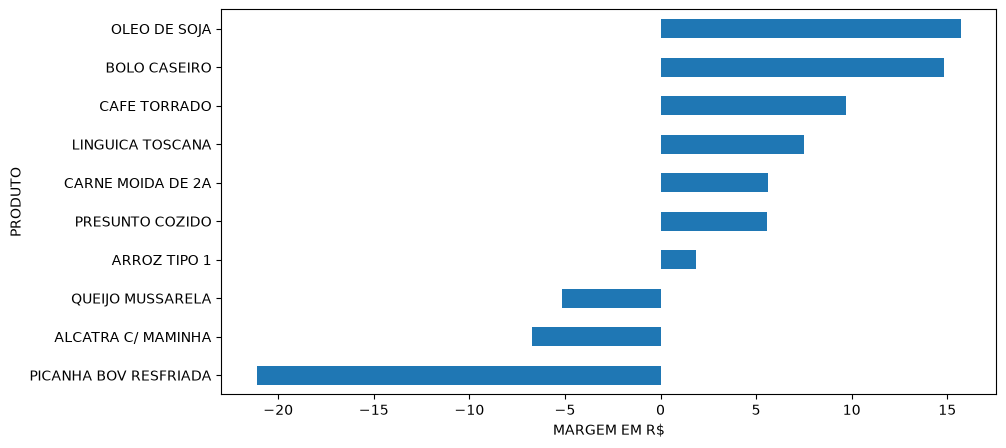

In [51]:
top_10_produtos.plot(
    kind='barh',
    x='NOME_PRODUTO',
    y='V_MARGEM',
    figsize=(10, 5),
    legend=False,
    xlabel='MARGEM EM R$',
    ylabel='PRODUTO'
)

<Axes: xlabel='QTD VENDAS', ylabel='CATEGORIA_BRUTA'>

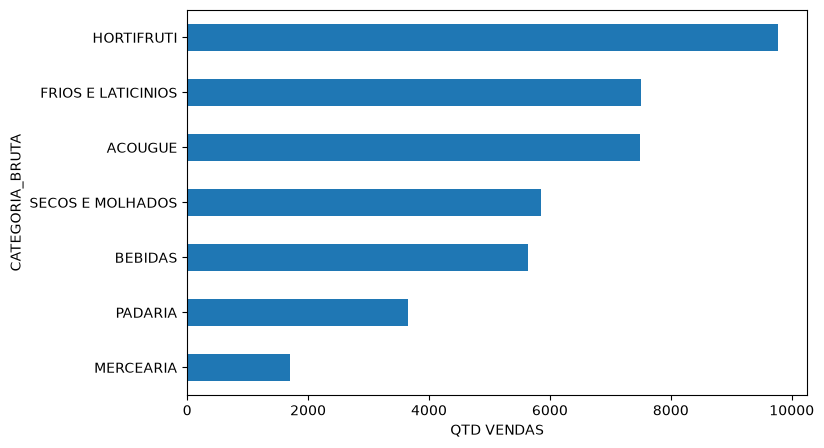

In [55]:
Cons_qtd = Vendas_graf.groupby(
    'CATEGORIA_BRUTA',
    as_index=False
)['QTD_VENDIDA'].sum()

Cons_qtd = Vendas_graf.groupby('CATEGORIA_BRUTA')['QTD_VENDIDA'].sum().reset_index()

Cons_qtd = Cons_qtd.sort_values(by='QTD_VENDIDA', ascending=True).head(10)



Cons_qtd.plot(
    kind='barh',
    x='CATEGORIA_BRUTA',
    y='QTD_VENDIDA',
    figsize=(8, 5),
    legend=False,
    xlabel='QTD VENDAS'
)


### Cria um grafico para cat x total

<Axes: xlabel='CATEGORIA', ylabel='FATURAMENTO R$'>

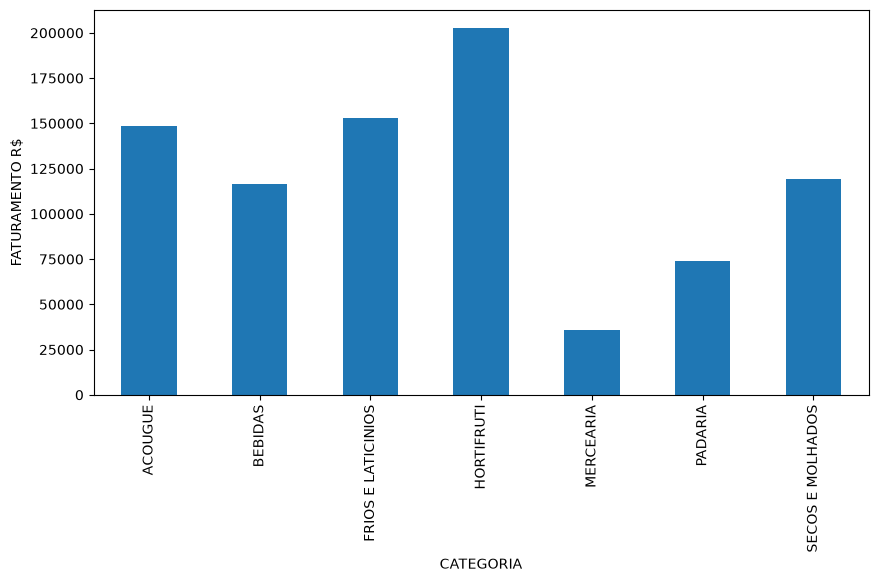

In [56]:
Cons_Unitario = Vendas_graf.groupby(
    'CATEGORIA_BRUTA',
    as_index=False
)['FATURAMENTO'].sum()


Cons_Unitario.plot(
    kind='bar',
    x='CATEGORIA_BRUTA',
    y='FATURAMENTO',
    figsize=(10, 5),
    legend=False,
    ylabel='FATURAMENTO R$',
    xlabel='CATEGORIA'
)

### Cria um grafico para cat x a média da margem de lucro

<Axes: xlabel='CATEGORIA', ylabel='MEDIA - MARGEM LUCRO - R$'>

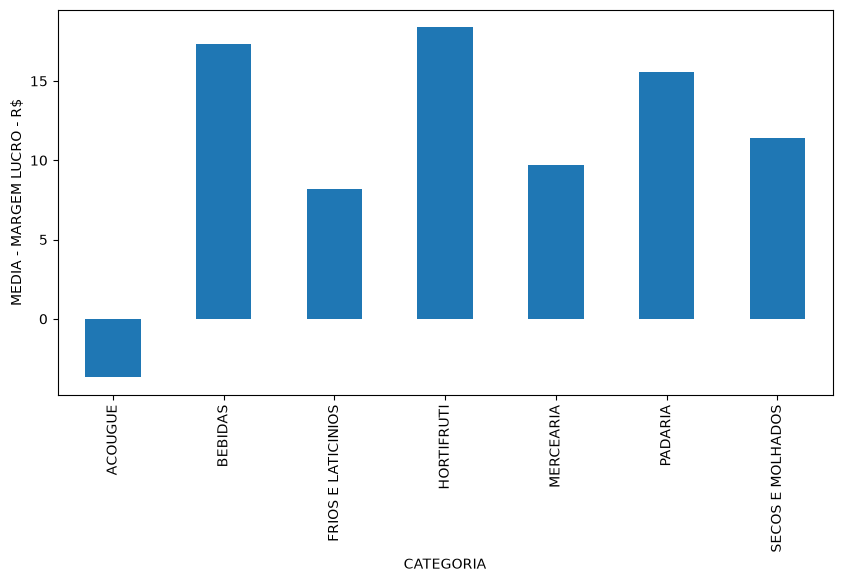

In [57]:
Cons_Unitario_2 = Vendas_graf.groupby(
    'CATEGORIA_BRUTA',
    as_index=False
)['V_MARGEM'].mean()


Cons_Unitario_2.plot(
    kind='bar',
    x='CATEGORIA_BRUTA',
    y='V_MARGEM',
    figsize=(10, 5),
    legend=False,
    ylabel='MEDIA - MARGEM LUCRO - R$',
    xlabel='CATEGORIA'
)

### Cria um grafico para cat x total

<Axes: xlabel='CATEGORIA', ylabel='SOMA MARGEM LUCRO'>

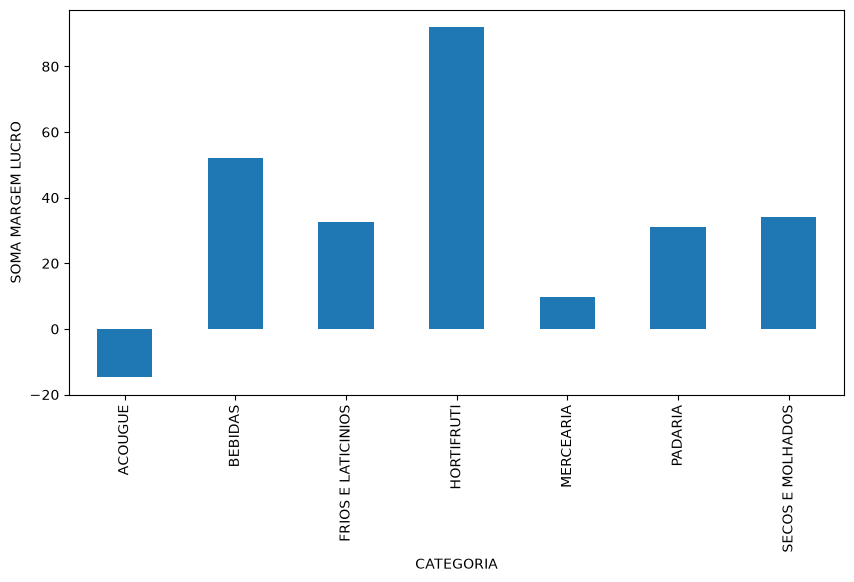

In [59]:
Cons_Unitario_2 = Vendas_graf.groupby(
    'CATEGORIA_BRUTA',
    as_index=False
)['V_MARGEM'].sum()


Cons_Unitario_2.plot(
    kind='bar',
    x='CATEGORIA_BRUTA',
    y='V_MARGEM',
    figsize=(10, 5),
    legend=False,
    ylabel='SOMA MARGEM LUCRO',
    xlabel='CATEGORIA'
)